# 01 - Análise exploratória
Trabalho Prático de Mineração de Dados, Grupo 8

Base: Predict Students' Dropout and Academic Success

### Análise Exploratória dos Dados

In [11]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

local_path = Path('../../data/data.csv')
dataset = pd.read_csv(local_path, sep=';')
dataset.head()

,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


In [12]:
X = dataset.drop(columns=['Target'])
y = dataset['Target']

print(f'registros: {X.shape[0]} | atributos: {X.shape[1]} | alvo: {y.name}')

tipos = pd.DataFrame({
    'role': ['Feature'] * X.shape[1] + ['Target'],
    'dtype_pandas': pd.concat([X, y], axis=1).dtypes.astype(str)
})
tipos

registros: 4424 | atributos: 36 | alvo: Target


,role,dtype_pandas
Marital status,Feature,int64
Application mode,Feature,int64
Application order,Feature,int64
Course,Feature,int64
Daytime/evening attendance\t,Feature,int64
Previous qualification,Feature,int64
Previous qualification (grade),Feature,float64
Nacionality,Feature,int64
Mother's qualification,Feature,int64
Father's qualification,Feature,int64


### Verificação de ausentes, duplicados e estatísticas gerais

In [13]:
print("Ausentes:", dataset.isnull().sum().sum())
print("Duplicados:", dataset.duplicated().sum())
display(dataset.describe().T[["min", "max", "mean", "std"]])

Ausentes: 0
Duplicados: 0


,min,max,mean,std
Marital status,1.00,6.000000,1.178571,0.605747
Application mode,1.00,57.000000,18.669078,17.484682
Application order,0.00,9.000000,1.727848,1.313793
Course,33.00,9991.000000,8856.642631,2063.566416
Daytime/evening attendance\t,0.00,1.000000,0.890823,0.311897
Previous qualification,1.00,43.000000,4.577758,10.216592
Previous qualification (grade),95.00,190.000000,132.613314,13.188332
Nacionality,1.00,109.000000,1.873192,6.914514
Mother's qualification,1.00,44.000000,19.561935,15.603186
Father's qualification,1.00,44.000000,22.275316,15.343108


### Analisar a distribuição da variável-alvo, identificando possíveis desbalanceamentos.

,Registros,Percentual (%)
Target,,
Graduate,2209,49.93
Dropout,1421,32.12
Enrolled,794,17.95


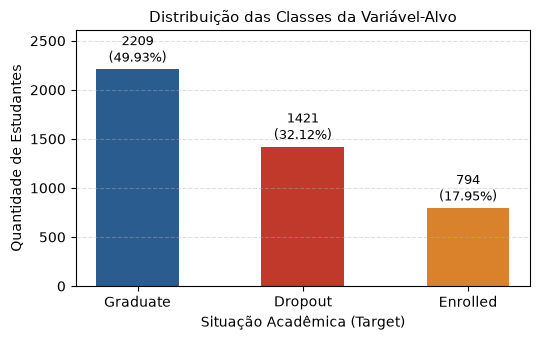

In [14]:
# Distribuição absoluta e percentual da variável-alvo
contagem = dataset["Target"].value_counts().reindex(["Graduate", "Dropout", "Enrolled"])
percentual = (contagem / len(dataset) * 100).round(2)

resumo_target = pd.DataFrame({
    "Registros": contagem,
    "Percentual (%)": percentual
})
display(resumo_target)

# Gráfico de barras para o artigo
fig, ax = plt.subplots(figsize=(5.5, 3.5))
cores = ["#2b5c8f", "#c0392b", "#d9822b"]
barras = ax.bar(contagem.index, contagem.values, color=cores, width=0.5)

ax.set_title("Distribuição das Classes da Variável-Alvo", fontsize=11)
ax.set_xlabel("Situação Acadêmica (Target)", fontsize=10)
ax.set_ylabel("Quantidade de Estudantes", fontsize=10)
ax.set_ylim(0, contagem.max() * 1.18)
ax.grid(axis="y", linestyle="--", alpha=0.4)

for barra, pct in zip(barras, percentual):
    altura = barra.get_height()
    ax.text(
        barra.get_x() + barra.get_width() / 2,
        altura + 35,
        f"{int(altura)}\n({pct:.2f}%)",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.tight_layout()
Path("../../media").mkdir(parents=True, exist_ok=True)
plt.savefig("../../media/distribuicao_target.png", dpi=300)
plt.show()

## Pré-Processamento
####  Limpeza e Separação $X$ e $y$

In [ ]:
from sklearn.preprocessing import LabelEncoder

# 1. Remove espaços e o caractere '\t' dos nomes das colunas
dataset.columns = dataset.columns.str.strip()

# 2. Separa atributos preditivos (X) e variável-alvo (y)
X = dataset.drop(columns=["Target"])
y_texto = dataset["Target"]

# 3. Codifica o Target para valores numéricos (0, 1, 2)
le = LabelEncoder()
y = le.fit_transform(y_texto)

print("Formato de X:", X.shape)
print("Mapeamento do Target:", {cls: idx for idx, cls in enumerate(le.classes_)})

Formato de X: (4424, 36)
Mapeamento do Target: {'Dropout': 0, 'Enrolled': 1, 'Graduate': 2}
Mapeamento do Target: None


### Agrupamento de Colunas e OneHotEncoder

In [16]:
from sklearn.preprocessing import OneHotEncoder

# 1. Categóricas nominais (codificadas como inteiros sem relação de ordem)
colunas_categoricas = [
    "Marital status", "Application mode", "Course", "Previous qualification",
    "Nacionality", "Mother's qualification", "Father's qualification",
    "Mother's occupation", "Father's occupation"
]

# 2. Binárias (já estão em 0 e 1)
colunas_binarias = [
    "Daytime/evening attendance", "Displaced", "Educational special needs",
    "Debtor", "Tuition fees up to date", "Gender", "Scholarship holder", "International"
]

# 3. Numéricas (discretas e contínuas — todas as demais)
colunas_numericas = [
    col for col in X.columns 
    if col not in colunas_categoricas and col not in colunas_binarias
]

# Verificação de contagem (precisa fechar exatamente 36)
total = len(colunas_categoricas) + len(colunas_binarias) + len(colunas_numericas)
print(f"Categóricas: {len(colunas_categoricas)} | Binárias: {len(colunas_binarias)} | Numéricas: {len(colunas_numericas)} | Total: {total}")

# Instanciando o codificador One-Hot
encoder_categorico = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

Categóricas: 9 | Binárias: 8 | Numéricas: 19 | Total: 36


### Normalização

In [17]:
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import StratifiedKFold

# 1. Montagem do pré-processador unificado
preprocessador = ColumnTransformer(
    transformers=[
        ("cat", encoder_categorico, colunas_categoricas),
        ("num", StandardScaler(), colunas_numericas),
        ("bin", "passthrough", colunas_binarias)
    ]
)

# 2. Validação cruzada estratificada em 5 partições (mesma semente para todos os modelos)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Teste rápido apenas para conferir quantas colunas finais são geradas
X_transformado = preprocessador.fit_transform(X)
print(f"Pré-processador pronto! Dimensão após One-Hot Encoding: {X_transformado.shape[1]} colunas.")

Pré-processador pronto! Dimensão após One-Hot Encoding: 247 colunas.
